# **Credit Risk Machine Learning** 

In [240]:
import pandas as pd 
import numpy as np 
import sklearn as sk 
import matplotlib.pyplot as plt 
import seaborn as sns
import scipy.stats as st 
import warnings
warnings.filterwarnings('ignore')

## **Loading The Dataset**

In [241]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## **EDA** 

In [242]:
df.shape

(32581, 12)

In [243]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


In [244]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


### **Missing Values**

In [245]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

### **Target Balance**

In [246]:
df['loan_status'].unique()

array([1, 0])

#### **Checking For Dataset Imbalance**

In [247]:
df_loan = df['loan_status'].value_counts().reset_index()
df_loan['percentage'] = 100 * df_loan['count'] / df_loan['count'].sum() 
df_loan

,loan_status,count,percentage
0,0,25473,78.183604
1,1,7108,21.816396


##### **How Many People Were Given a Loan?**

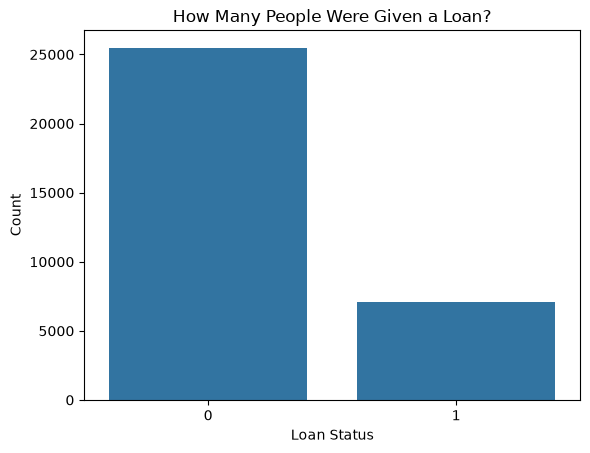

In [248]:
sns.countplot(data = df, x ='loan_status')
plt.title('How Many People Were Given a Loan?')
plt.xlabel('Loan Status')
plt.ylabel('Count')
plt.show()

##### **How Many People Defaulted & How Many People Repaid The Loan**

In [249]:
df_defaulted = df['cb_person_default_on_file'].value_counts().reset_index()
df_defaulted['percentage'] = 100 * df_defaulted['count'] / df_defaulted['count'].sum() 
df_defaulted

,cb_person_default_on_file,count,percentage
0,N,26836,82.367024
1,Y,5745,17.632976


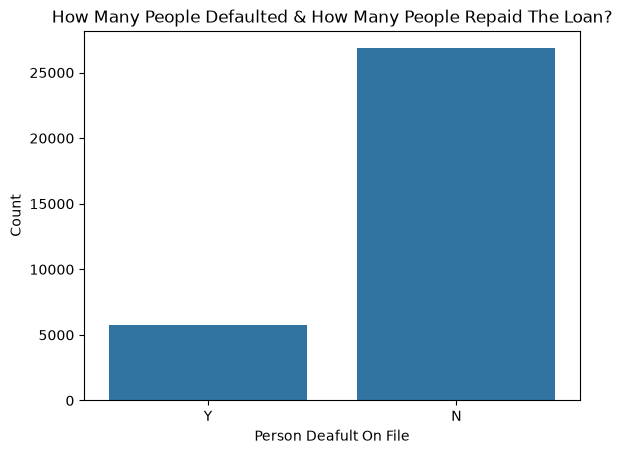

In [250]:
sns.countplot(data = df, x ='cb_person_default_on_file')
plt.title('How Many People Defaulted & How Many People Repaid The Loan?')
plt.xlabel('Person Deafult On File')
plt.ylabel('Count')
plt.show()

### **Outliers & Impossible Values** 

In [251]:
numerical_cols = df.select_dtypes(include= np.number).columns
numerical_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='str')

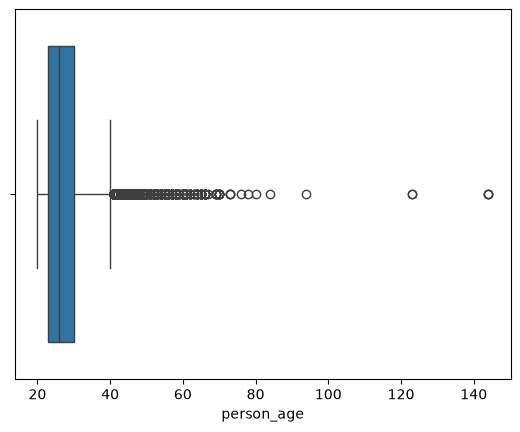

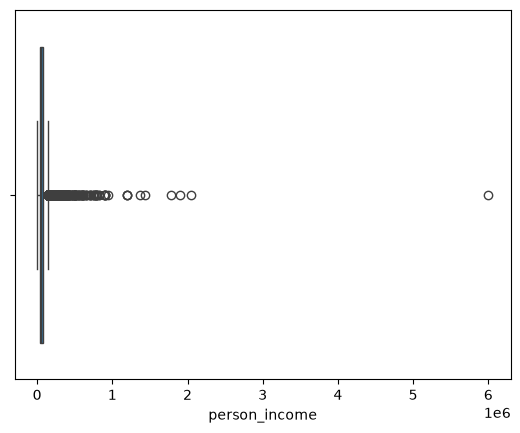

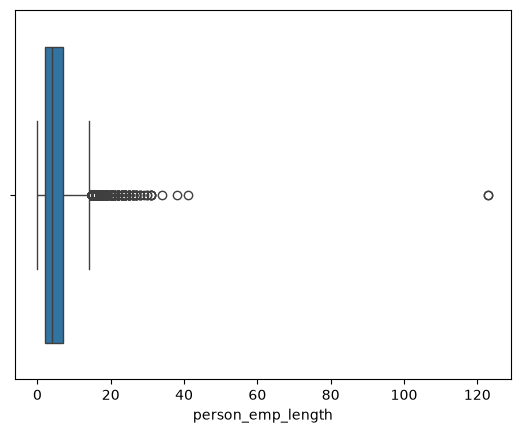

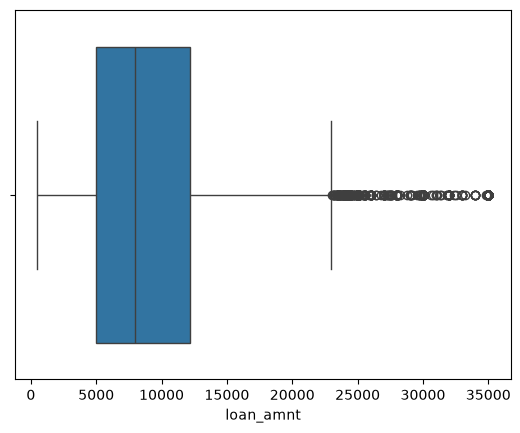

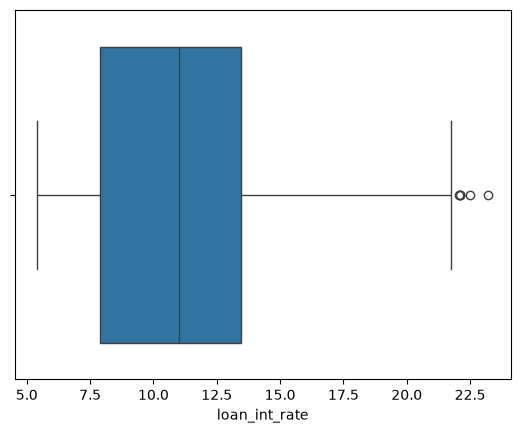

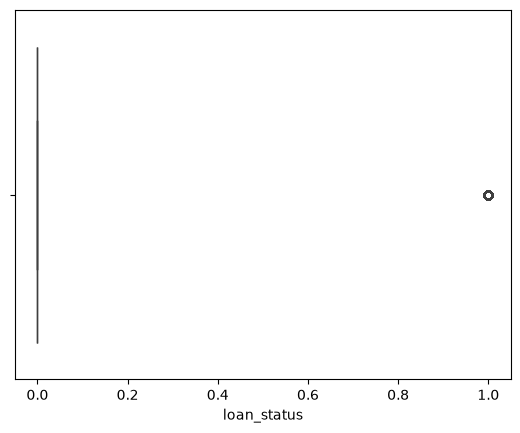

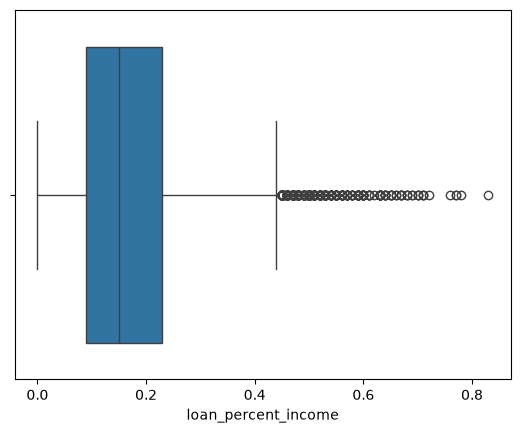

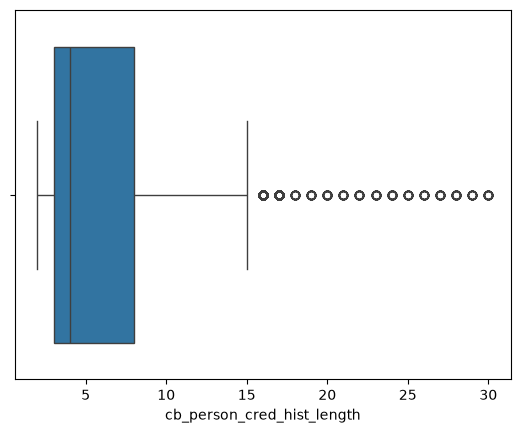

In [252]:
for i in numerical_cols:
    sns.boxplot(x=df[i])
    plt.show()

In [253]:
(df['person_age'] > 100).sum()

np.int64(5)

In [254]:
df[df['person_age'] > 100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


In [255]:
(df['person_emp_length'] > 60).sum()

np.int64(2)

In [256]:
df[df['person_emp_length'] > 60]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


### **Correlations** 

<Axes: >

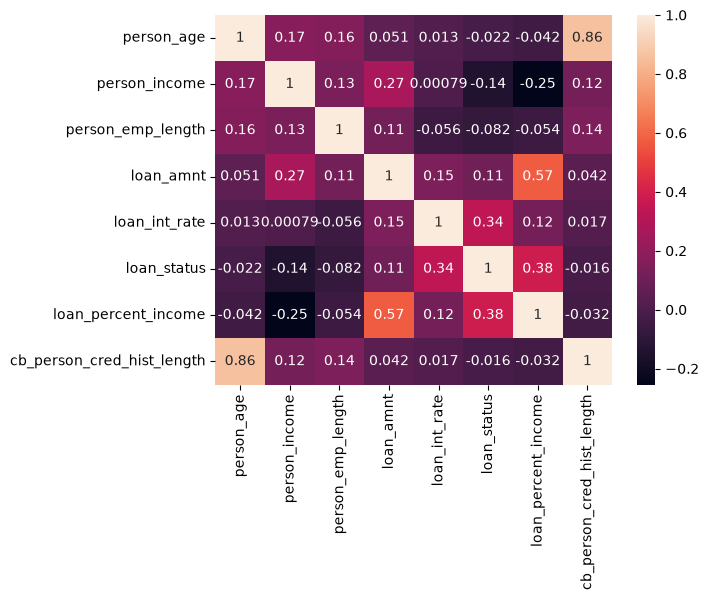

In [257]:
sns.heatmap(df.corr(numeric_only = True), annot= True)

## **Data Cleanig & Validation** 

In [258]:
credit_df = df.copy()

#### **Removing Duplicates** 

In [259]:
print(f' Original Rows: {len(df)}')

# Removing Duplicates 
credit_df.drop_duplicates(inplace=True)
print(f'Rows After Removing Duplicates: {len(credit_df)}')
print(f'Rows Removed: {len(df) - len(credit_df)}' )

 Original Rows: 32581
Rows After Removing Duplicates: 32416
Rows Removed: 165


#### **Impossible Values** 

In [260]:
# Removing ages below 18 or above 100
row_count = len(credit_df) 
credit_df = credit_df[(credit_df['person_age'] >= 18) & (credit_df['person_age'] <= 100)] 
print(f'Rows Removed : {row_count - len(credit_df)}')
print(f'Rows Remaining: {len(credit_df)}')

Rows Removed : 5
Rows Remaining: 32411


In [261]:
# Removing employment length greater than age or extreme outliers (>60)
row_count = len(credit_df)
credit_df = credit_df[credit_df['person_emp_length'] <= credit_df['person_age']]
credit_df = credit_df[credit_df['person_emp_length'] <= 60]
print(f'Rows Removed : {row_count - len(credit_df)}')
print(f'Rows Remaining: {len(credit_df)}')

Rows Removed : 889
Rows Remaining: 31522


**894 Rows Removed in Total**

## **Train Test Split**

In [262]:
# We are splitting the data before encoding so that there is no data leakage

x = credit_df.drop('loan_status', axis = 1)
y = credit_df['loan_status']

In [263]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state= 42, stratify= y)

In [264]:
numerical_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length'] 
categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

## **Handle Class Imbalance** 

In [265]:
y_train.value_counts()

loan_status
0    18536
1     5105
Name: count, dtype: int64

In [266]:
neg, pos = np.bincount(y_train)
print(neg)
print(pos)

18536
5105


In [267]:
scale_weights = neg / pos

## **Data Preprocessing - Pieplines & Column Transformer**

In [268]:
from sklearn.pipeline import Pipeline 
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [269]:
# Pipeline for logistic regression 
# 1. Pipeline for Logistic Regression
preprocessor_lr = ColumnTransformer(
    transformers = [
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_cols),
        
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols) 
    ]
)

preprocessor_lr

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [270]:
# Pipeline for XGBoost 
# Impute numeric only (No Scaling)
# For categorical columns only impute and one hot encoding 

# 2. Pipeline for XGBoost
preprocessor_xg = ColumnTransformer(
    transformers = [
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
        ]), numerical_cols),
        
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)  # <--- Make sure this is here too!
    ]
)

preprocessor_xg

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## **Cross Validaition**    

In [271]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [272]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'roc_auc': 'roc_auc', 'accuracy' : 'accuracy', 'precision': 'precision', 'recall' : 'recall', 'f1': 'f1' }

In [273]:
# Logistic Regression 

from sklearn.linear_model import LogisticRegression

lr_cv_regression = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(
        max_iter=1000, 
        class_weight= 'balanced',
        random_state=42))
])

lr_cv_regression

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [274]:
# XGBoost Model 
from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimators = 300, 
        max_depth = 5, 
        learning_rate = 0.1, 
        scale_pos_weight = scale_weights, 
        random_state = 42
    ))
])

xgb_cv_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [275]:
for cv_name, pipe in [
    ('Logistic Regression', lr_cv_regression), 
    ('XGBClassifier', xgb_cv_pipeline)]:
    cv_results = cross_validate(pipe, x_train, y_train, cv = cv, scoring = scoring, n_jobs=-1)
    print(cv_name)
    print(f"ROC-AUC: {cv_results['test_roc_auc'].mean():.4f}")
    print(f"Accuracy: {cv_results['test_accuracy'].mean():.4f}")
    print(f"Precision: {cv_results['test_precision'].mean():.4f}")
    print(f"Recall: {cv_results['test_recall'].mean():.4f}")
    print(f"f1: {cv_results['test_f1'].mean():.4f}")
    print()

Logistic Regression
ROC-AUC: 0.8717
Accuracy: 0.8119
Precision: 0.5452
Recall: 0.7779
f1: 0.6410

XGBClassifier
ROC-AUC: 0.9468
Accuracy: 0.9189
Precision: 0.8233
Recall: 0.7955
f1: 0.8091



## **Evaluation Helper Function**

In [276]:
# We will evaluate our models using this funciton 

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve, classification_report
def evaluate_model(model_name, model, x_test, y_test, threshold = None):
    y_pred = model.predict(x_test)
    y_pred_prob = model.predict_proba(x_test)[:,1]
    
    if threshold:
        y_pred = (y_pred_prob > threshold).astype(int)
    else:
        y_pred = model.predict(x_test)
    
    #Metrices
    Accuracy = accuracy_score(y_test, y_pred) # Overall Model Performance 
    Precision = precision_score(y_test, y_pred) # How many 1's are actually right
    Recall= recall_score(y_test, y_pred) # Out of everything how much did we manage to find
    f1 = f1_score(y_test, y_pred) # Harmonic mean of precision and recall 
    
    # Confusion Matrix 
    cm = confusion_matrix(y_test, y_pred)
    Classification_Report = classification_report(y_test, y_pred)
    
    print(f"{model_name:} Matrics:")
    print(f"Accuracy: {Accuracy:.2f}")
    print(f"precision: {Precision:.2f}")
    print(f"Recall : {Recall:.2f}")
    print(f"f1: {f1:.2f}")
    print(Classification_Report)
   
    # Plotting the Confusion Matrix
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title (f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()
    
    
    # Plotting ROC-AUC Curve --> Area under curve --> shows how precision and recall correlate 
    precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precisions)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision Recall Curve")    

## **Baseline Model**

In [277]:
baseline_model = Pipeline([
    ('Preprocessor', preprocessor_lr),
    ('Classifier', LogisticRegression(class_weight= 'balanced'))
])

baseline_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('Classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

Baseline Logistics Regression Matrics:
Accuracy: 0.82
precision: 0.55
Recall : 0.78
f1: 0.65
              precision    recall  f1-score   support

           0       0.93      0.82      0.88      6179
           1       0.55      0.78      0.65      1702

    accuracy                           0.82      7881
   macro avg       0.74      0.80      0.76      7881
weighted avg       0.85      0.82      0.83      7881



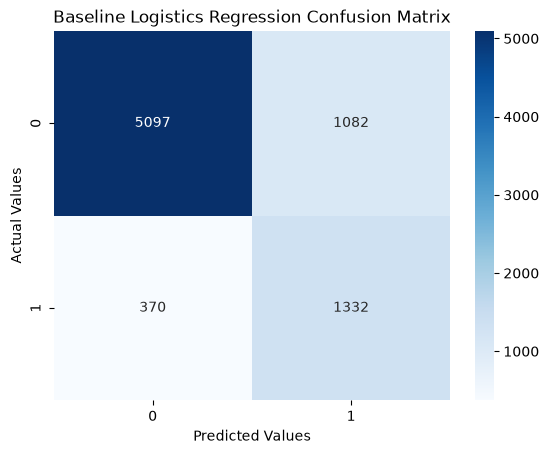

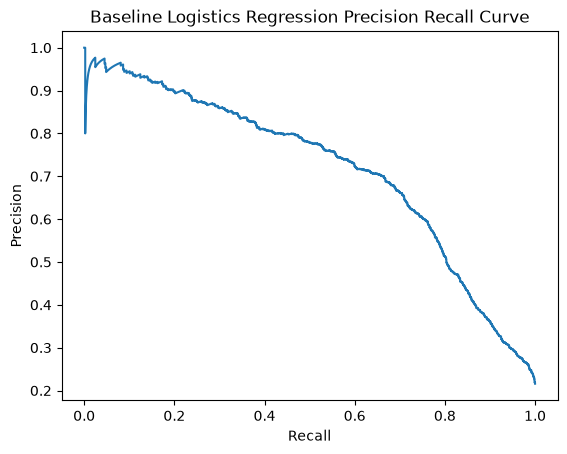

In [278]:
evaluate_model("Baseline Logistics Regression", baseline_model, x_test, y_test)

## **XGBoost Model** 

In [279]:
xg_model = Pipeline([
    ('Preprocessor', preprocessor_xg),
    ('Classifier', XGBClassifier(learning_rate = 0.1, scale_pos_weights = scale_weights, random_state = 42))
])

xg_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('Classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

### **Evaluation Before Hyper Parameter Tuning** 

XGBoost Matrics:
Accuracy: 0.93
precision: 0.97
Recall : 0.72
f1: 0.82
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      6179
           1       0.97      0.72      0.82      1702

    accuracy                           0.93      7881
   macro avg       0.95      0.86      0.89      7881
weighted avg       0.94      0.93      0.93      7881



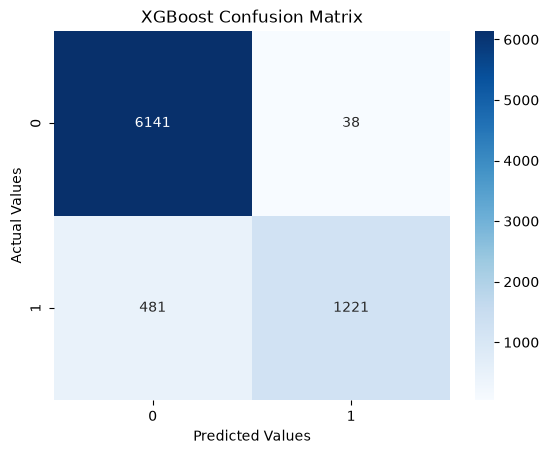

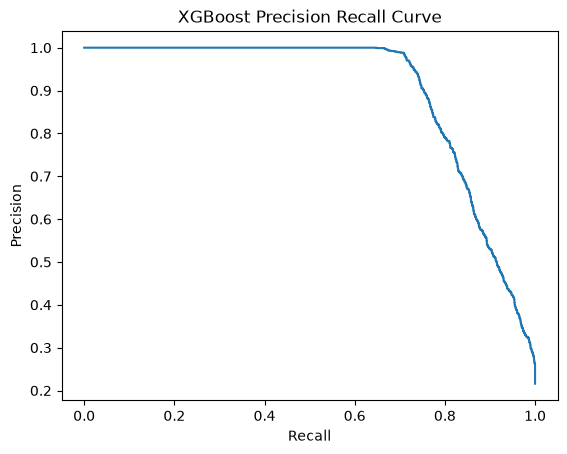

In [280]:
evaluate_model("XGBoost", xg_model, x_test, y_test)

### **Hyper Parameter Tuning**

In [281]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

param_grid = {
    "Classifier__n_estimators": randint(150, 600),
    "Classifier__max_depth": randint(3,9),
    "Classifier__learning_rate": uniform(0.01,0.05),
    "Classifier__subsample": uniform(0.6,0.4), # picks random rows 
    "Classifier__colsample_bytree": uniform(0.6,0.4), # column sampling 
    "Classifier__min_child_weight": randint(1,10), # do we improve with every split
    "Classifier__gamma" : uniform(0,5) # lower gamma --> higher splits --> complex tree --> higher overfitting risk
}

In [282]:

random_search_xg = RandomizedSearchCV(
    xg_model, 
    param_distributions=param_grid, 
    n_iter=200, 
    cv = cv, 
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
    )

In [283]:
print("Running RandomizedSearchCV... 🚀")
random_search_xg.fit(x_train,y_train)

Running RandomizedSearchCV... 🚀
Fitting 5 folds for each of 200 candidates, totalling 1000 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'Classifier__colsample_bytree': <scipy.stats....002034007B860>, 'Classifier__gamma': <scipy.stats....002036800CF50>, 'Classifier__learning_rate': <scipy.stats....0020369C10C90>, 'Classifier__max_depth': <scipy.stats....002036EA0F980>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",200
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index

In [284]:
print(f"Score After Hyper Parameter Tuning: {random_search_xg.best_score_:.2f}")

Score After Hyper Parameter Tuning: 0.90


In [285]:
random_search_xg.best_params_

{'Classifier__colsample_bytree': np.float64(0.7223622926048104),
 'Classifier__gamma': np.float64(0.041195798047161114),
 'Classifier__learning_rate': np.float64(0.05768219431945081),
 'Classifier__max_depth': 6,
 'Classifier__min_child_weight': 3,
 'Classifier__n_estimators': 379,
 'Classifier__subsample': np.float64(0.914582279794107)}

In [286]:
best_model_xg = random_search_xg.best_estimator_

XGBoost_Tuned Matrics:
Accuracy: 0.94
precision: 0.97
Recall : 0.73
f1: 0.83
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      6179
           1       0.97      0.73      0.83      1702

    accuracy                           0.94      7881
   macro avg       0.95      0.86      0.90      7881
weighted avg       0.94      0.94      0.93      7881



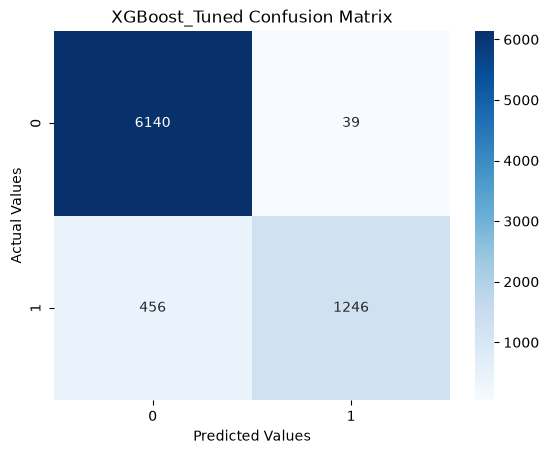

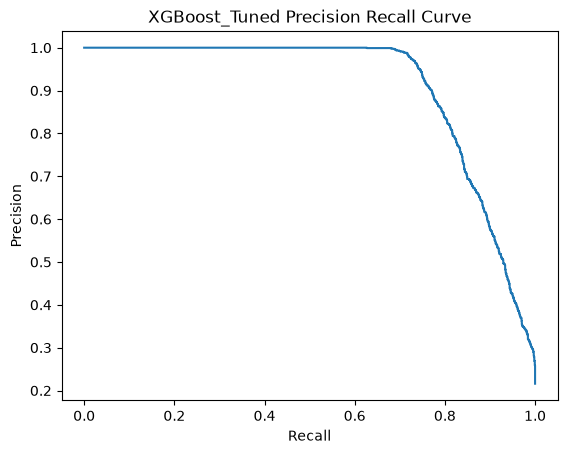

In [287]:
evaluate_model("XGBoost_Tuned", random_search_xg, x_test, y_test)

## **Optimmizing The Classification Threshold**

XGBoost Matrics:
Accuracy: 0.94
precision: 0.96
Recall : 0.74
f1: 0.83
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      6179
           1       0.96      0.74      0.83      1702

    accuracy                           0.94      7881
   macro avg       0.95      0.86      0.90      7881
weighted avg       0.94      0.94      0.93      7881



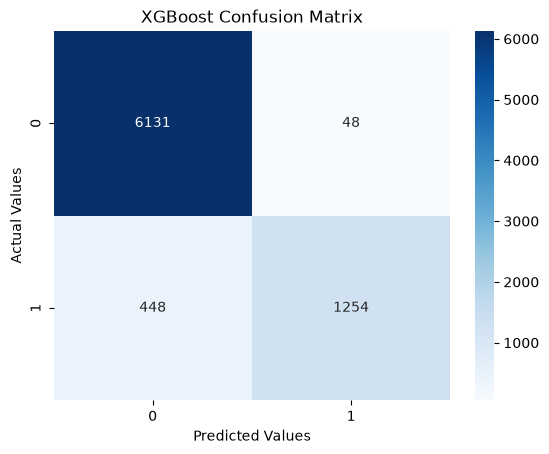

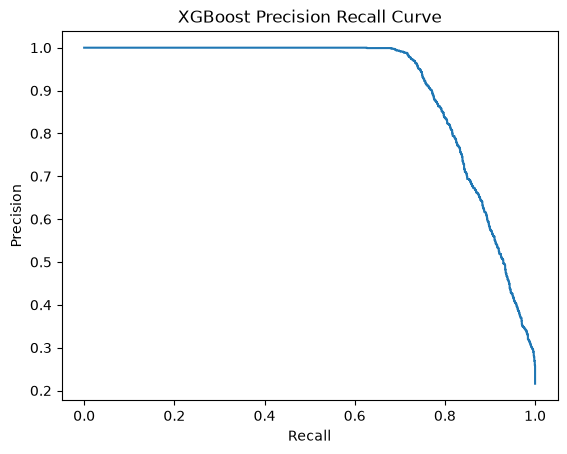

In [288]:
# Probability of class 1 from XGBoost
prob = best_model_xg.predict_proba(x_test)[:, 1]

# Threshold Calculate Precision & Recall
precisions, recalls, thresholds = precision_recall_curve(y_test,prob)

# Calculate F1 score for each threshold
f1 = (2 * (precisions * recalls))/ (precisions + recalls + 1e-9)

# Get the threshold that produces the maximum f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best] 

# Evaluate the model using that threshold 
evaluate_model("XGBoost", best_model_xg,x_test, y_test, best_threshold)

#### **Ading best threshold to evaluation function**

In [289]:
# We will evaluate our models using this funciton 

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve, classification_report
def evaluate_model(model_name, model, x_test, y_test, threshold = None):
    y_pred = model.predict(x_test)
    y_pred_prob = model.predict_proba(x_test)[:,1]
    
    if threshold:
        y_pred = (y_pred_prob > threshold).astype(int)
    else:
        y_pred = model.predict(x_test)
    
    #Metrices
    Accuracy = accuracy_score(y_test, y_pred) # Overall Model Performance 
    Precision = precision_score(y_test, y_pred) # How many 1's are actually right
    Recall= recall_score(y_test, y_pred) # Out of everything how much did we manage to find
    f1 = f1_score(y_test, y_pred) # Harmonic mean of precision and recall 
    
    # Confusion Matrix 
    cm = confusion_matrix(y_test, y_pred)
    Classification_Report = classification_report(y_test, y_pred)
    
    print(f"{model_name:} Matrics:")
    print(f"best_threshold: {best_threshold:.2f}")
    print(f"Accuracy: {Accuracy:.2f}")
    print(f"precision: {Precision:.2f}")
    print(f"Recall : {Recall:.2f}")
    print(f"f1: {f1:.2f}")
    print(Classification_Report)
   
    # Plotting the Confusion Matrix
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title (f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()
    
    
    # Plotting ROC-AUC Curve --> Area under curve --> shows how precision and recall correlate 
    precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precisions)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision Recall Curve")    

In [290]:
best_threshold

np.float32(0.46333998)

## **Probability Calibration**

In [291]:
# Calibrate XGBoost Model 
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

calibrated_model = CalibratedClassifierCV(
    best_model_xg, 
    method="sigmoid",
    cv=5)

calibrated_model.fit(x_train,y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","Pipeline(step...=None, ...))])"
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...0020369C0A6D0>, <

In [292]:
# Get the proabilities  

uncalibrated = best_model_xg.predict_proba(x_test)[:, 1]
uncalibrated

array([0.00428295, 0.00384071, 0.07122428, ..., 0.05964701, 0.04422426,
       0.21234088], shape=(7881,), dtype=float32)

In [293]:
calibrated = calibrated_model.predict_proba(x_test)[:, 1]
calibrated

array([0.02993315, 0.02938048, 0.04811742, ..., 0.04879357, 0.03978365,
       0.13849351], shape=(7881,))

In [294]:
# Create calibration curves 
actual_uncal, pred_uncal = calibration_curve(y_test, uncalibrated, n_bins = 10)

In [295]:
actual_cal, pred_cal = calibration_curve(y_test, calibrated, n_bins = 10)

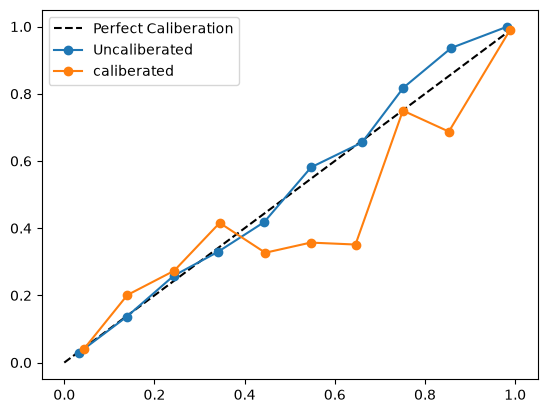

In [296]:
# Plot 

plt.plot([0,1], [0,1], "k--", label = "Perfect Caliberation")

plt.plot(
    pred_uncal,
    actual_uncal,
    "o-",
    label = "Uncaliberated"
)

plt.plot(
    pred_cal,
    actual_cal,
    "o-",
    label = "caliberated"
)
plt.legend()

## **SHAP Interpretation - Global & Local** 

In [297]:
import shap

In [298]:
# Getting the trained XGBoost classifier out of the pipeline 

XGB_classifier = xg_model.named_steps['Classifier']

In [299]:
# Transforming x test using the same preprocessing used for training 

x_test_transformed = xg_model.named_steps['Preprocessor'].transform(x_test)

In [300]:
xg_model.named_steps.keys()

dict_keys(['Preprocessor', 'Classifier'])

In [301]:
# Get the feature names after one-hot encoding, so plots are readable 

feature_names = xg_model.named_steps['Preprocessor'].get_feature_names_out()

In [302]:
# Coverting to a dataframe for clearner SHAP plots 
x_test_df = pd.DataFrame(x_test_transformed, columns = feature_names)
x_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,27.0,58000.0,1.0,8000.0,11.36,0.14,7.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,43.0,60000.0,2.0,9250.0,5.79,0.15,17.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,41.0,50780.0,14.0,6000.0,10.99,0.12,17.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,30.0,125000.0,14.0,7000.0,10.99,0.06,7.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,21.0,25000.0,2.0,3600.0,9.91,0.14,4.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7876,22.0,60000.0,6.0,10000.0,8.90,0.17,3.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7877,37.0,103000.0,1.0,10000.0,15.62,0.10,12.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
7878,23.0,37344.0,0.0,3200.0,12.68,0.09,2.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
7879,32.0,45000.0,7.0,4000.0,7.49,0.09,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [303]:
# Creating SHAP explainer built for tree base model 

explainer = shap.TreeExplainer(XGB_classifier)

In [304]:
# Calculating SHAP values for every row in the test data set 
shap_values = explainer.shap_values(x_test_df)

### **Global Explainations**

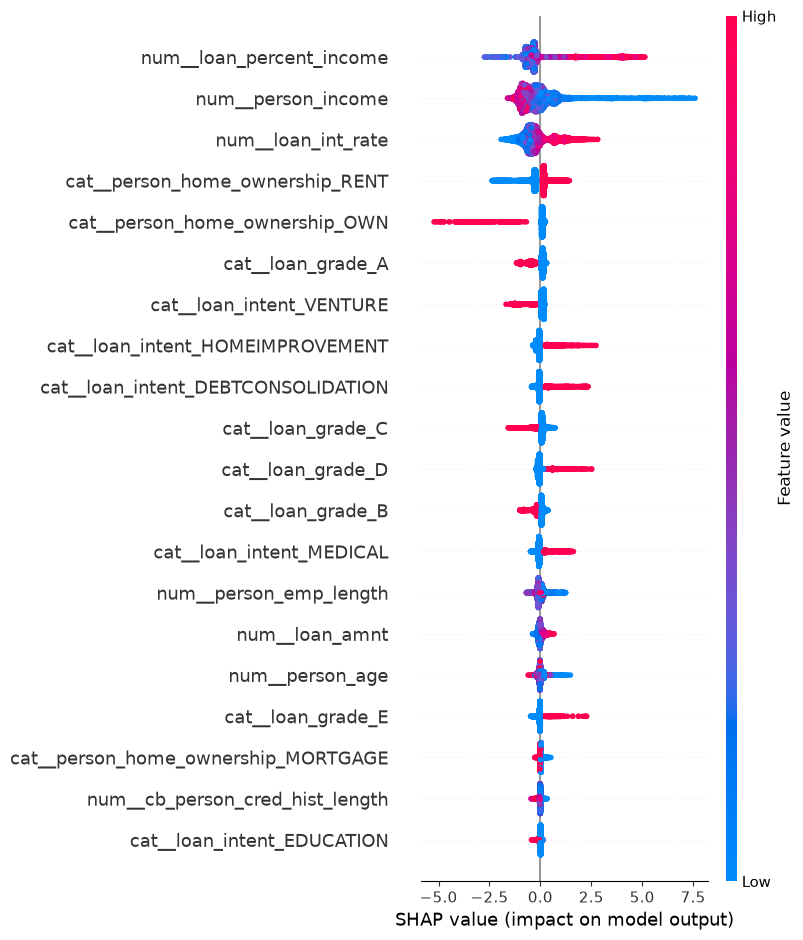

In [305]:
shap.summary_plot(shap_values, x_test_df)

#### **Local Explaination**

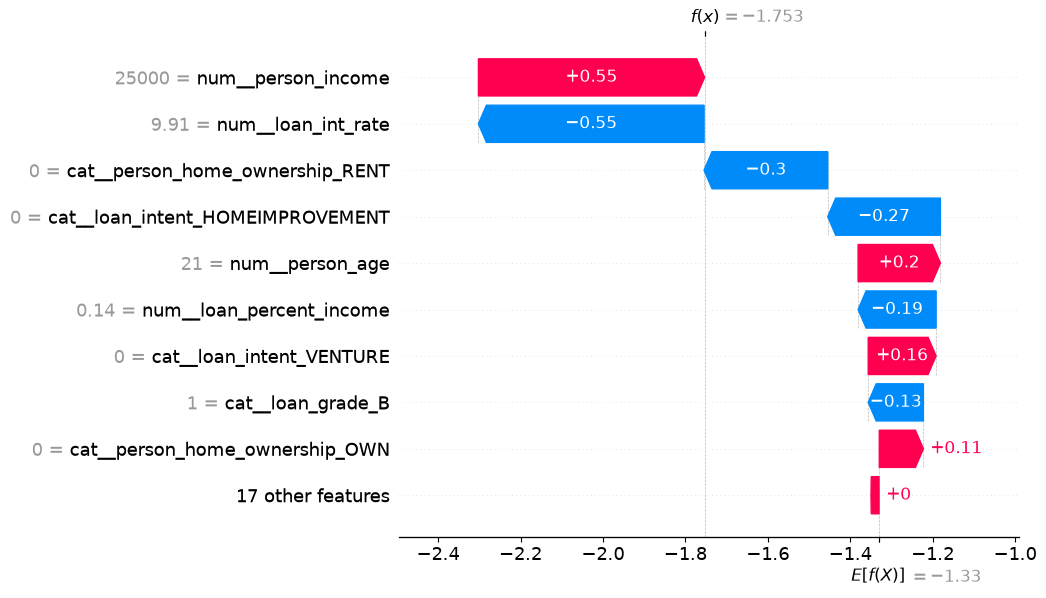

In [306]:
# Pick one row to explain 
row_index = 4

# Draw a waterfall plot showing how each feature pushed the prediction up or down
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value, # what did model predict for this data point 
        data = x_test_df.iloc[row_index], # Actual Values 
        feature_names = feature_names
    )
)

## **Analyzing False Positve & False Negative**

In [307]:
# Getting predictions from the best performing XGBoost model

y_pred = best_model_xg.predict(x_test)

In [308]:
# Creating a dataframe to easily compare the actual and predicited values 
result_df = x_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [309]:
# Identify False Positive --> model predicted 1 but the actual was 0 
false_postive = result_df[(result_df['actual']==0) & (result_df['predicted'] == 1)]
false_postive

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
18795,30,14800,RENT,5.0,DEBTCONSOLIDATION,A,1200,8.00,0.08,N,9,0,1
20776,29,42000,RENT,3.0,MEDICAL,D,5000,15.99,0.12,Y,6,0,1
27088,33,12000,RENT,0.0,MEDICAL,B,1500,11.83,0.13,N,6,0,1
3826,24,32500,RENT,5.0,MEDICAL,D,4000,16.29,0.12,Y,3,0,1
28140,27,31200,OWN,0.0,HOMEIMPROVEMENT,F,14000,18.09,0.45,Y,9,0,1
18796,28,15600,RENT,0.0,EDUCATION,B,1200,12.53,0.08,N,8,0,1
19396,34,32000,RENT,9.0,MEDICAL,D,3000,14.59,0.09,Y,7,0,1
31978,41,140000,MORTGAGE,2.0,EDUCATION,E,15000,17.88,0.11,N,11,0,1
9613,25,34000,RENT,8.0,PERSONAL,D,8400,NaN,0.25,N,4,0,1
5148,25,44000,MORTGAGE,2.0,VENTURE,D,12000,14.54,0.27,N,2,0,1


In [310]:
# Identify False Negative --> model predicted 0 bu thte actual was 1 
false_negative = result_df[(result_df['actual']==1) & (result_df['predicted'] == 0)]
false_negative

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
18468,27,98000,RENT,11.0,HOMEIMPROVEMENT,D,20000,16.00,0.20,N,8,1,0
21503,27,42000,MORTGAGE,4.0,PERSONAL,C,2850,13.48,0.07,N,7,1,0
31997,47,44004,RENT,2.0,PERSONAL,B,8000,NaN,0.18,N,15,1,0
3893,26,33000,MORTGAGE,0.0,HOMEIMPROVEMENT,C,9000,13.72,0.27,N,2,1,0
12715,24,62050,MORTGAGE,1.0,MEDICAL,C,5600,14.65,0.08,N,4,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
31693,41,17000,RENT,0.0,PERSONAL,C,1500,15.23,0.09,N,13,1,0
10723,24,64000,MORTGAGE,7.0,VENTURE,F,4000,20.89,0.06,N,2,1,0
10203,24,59964,MORTGAGE,0.0,DEBTCONSOLIDATION,B,1275,10.99,0.02,N,4,1,0
26672,29,98000,MORTGAGE,2.0,HOMEIMPROVEMENT,B,7925,10.59,0.08,N,9,1,0


In [311]:
print(f"False Positve: {len(false_postive)}")
print(f"False Negative: {len(false_negative)}")
print(f"Flase Negative has higher chances")

False Positve: 39
False Negative: 456
Flase Negative has higher chances


In [312]:
## Saving The Best Performing Model 
import joblib 
joblib.dump(best_model_xg, 'credit_risk_model.pkl')

['credit_risk_model.pkl']

In [313]:
joblib.dump(best_threshold, 'best_threshold.pkl')

['best_threshold.pkl']